# Mudcard 
- **I still don'tunderstand why this is the case: the coefficients of linear and logistic regression can be used as a measure of feature importance ONLY IF all features have the same mean (usually 0) and the same standard deviation. How can one-hot encoded and ordinal features have means and standard deviation?**
    - I'm not sure I understand the question. 
    - Any numerical feature has a mean and a standard deviation.
    - A one-hot encoded feature contains 0s and 1s. If you calculate the mean of a one-hot encoded feature, it is between 0 and 1 depending on the fraction of 0s and 1s. The maximum stdev is 0.5 if the feature contains exactly 50-50 0s and 1s and drops towards zero as the proprtion of 0s increases.
    - An ordinal feature contain integer numbers from 0 to n-1 where n is the number of ordinal categories. Such features also have a mean and stdev.

# Local feature importance metrics
By the end of this module, you will be able to
- Describe motivation behind local feature importance metrics
- Apply SHAP
- Describe LIME

## <font color='LIGHTGRAY'>Local feature importance metrics</font>
<font color='LIGHTGRAY'>By the end of this module, you will be able to</font>
- **Describe motivation behind local feature importance metrics**
- <font color='LIGHTGRAY'>Apply SHAP</font>
- <font color='LIGHTGRAY'>Describe LIME</font>

## Motivation
- can we trust the model?
   - global feeature importance: does the model make predictions based on reasonable features?
   - local feature importance: can we trust the model's prediction for one specific data point?
- global feature importance is often not enough especially when you work with human data
   - medical: the doctor needs to be able to explain the reasoning behind the model prediction to the patient
   - finance: customer wants to know why they were declined a loan/mortgage/credit card/etc

## Global vs. local importance
- global: one value per feature, it is a vector of shape $(n_{ftrs})$
    - it describes how important each feature is generally
- local: one value per feature and data points, it is a 2D array with a shape of $(n_{points},n_{ftrs})$ - the same shape as your feature matrix
    - it describes how important each feature is for predicting one particular data point

## Motivation
<center><img src="../figures/int_vs_acc.jpg" width="600"></center>

- local feature importance improves the interpretability of complex models 
- check out [this page](https://en.wikipedia.org/wiki/MNIST_database) for a good example

## <font color='LIGHTGRAY'>Local feature importance metrics</font>
<font color='LIGHTGRAY'>By the end of this module, you will be able to</font>
- <font color='LIGHTGRAY'>Describe motivation behind local feature importance metrics</font>
- **Apply SHAP**
- <font color='LIGHTGRAY'>Describe LIME</font>

# SHAP values
- one way to calculate local feature importances
- it is based on Shapely values from game theory
- read more [here](https://arxiv.org/abs/1802.03888), [here](https://github.com/slundberg/shap), and [here](https://christophm.github.io/interpretable-ml-book/shap.html)

### Cooperative game theory
- A set of *m* players in a coalition generate a surplus.
- Some players contribute more to the coalition than others (different bargaining powers).
- How important is each player to the coalition?
- How should the surplus be divided fairly amongst the players?

### Cooperative game theory <font color='red'>applied to feature attribution</font>
- A set of *m* <font color='red'>features</font> in a <font color='red'>model</font> generate a <font color='red'>prediction</font>.
- Some <font color='red'>features</font> contribute more to the <font color='red'>model</font> than others (different <font color='red'>predictive</font> powers).
- How important is each <font color='red'>feature</font> to the <font color='red'>model</font>?
- How should the <font color='red'>prediction</font> be divided amongst the <font color='red'>features</font>?

## How is it calculated?
### $\Phi_i = \sum_{S\subseteq M\setminus i}  \frac{|S|!(M - |S| - 1)!} {M!} [f_x(S\cup i) - f_x(S)]$

- $\Phi_i$ - the contribution of feature $i$
- $M$ - the number of features
- $S$ - a set of features excluding $i$, a vector of 0s and 1s (0 if a feature is missing)
- $|S|$ - the number of features in $S$
- $f_x(S)$ - the prediction of the model with features $S$

## How is it calculated?
### $\Phi_i = \sum_{S\subseteq M\setminus i} \color{blue}{\frac{|S|!(M - |S| - 1)!} {M!}}\color{red}{[f_x(S\cup i) - f_x(S)]}$
- <font color='red'>the difference feature $i$ makes in the prediction: </font>
    - <font color='red'>$f_x(S\cup i)$ - the prediction with feature $i$</font>
    - <font color='red'>$f_x(S)$ - the prediction without feature $i$</font>
- loop through all possible ways a set of S features can be selected from the M features excluding i
- <font color='blue'>weight the contribution based on how many ways we can select $|S|$ features</font>

# Quiz 1

In [1]:
import numpy as np
import pandas as pd
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pylab as plt

df = pd.read_csv('../data/adult_data.csv')
label = 'gross-income'
y = df[label]
df.drop(columns=[label],inplace=True)
X = df
ftr_names = X.columns
print(X.head())
print(y)

   age          workclass  fnlwgt   education  education-num  \
0   39          State-gov   77516   Bachelors             13   
1   50   Self-emp-not-inc   83311   Bachelors             13   
2   38            Private  215646     HS-grad              9   
3   53            Private  234721        11th              7   
4   28            Private  338409   Bachelors             13   

        marital-status          occupation    relationship    race      sex  \
0        Never-married        Adm-clerical   Not-in-family   White     Male   
1   Married-civ-spouse     Exec-managerial         Husband   White     Male   
2             Divorced   Handlers-cleaners   Not-in-family   White     Male   
3   Married-civ-spouse   Handlers-cleaners         Husband   Black     Male   
4   Married-civ-spouse      Prof-specialty            Wife   Black   Female   

   capital-gain  capital-loss  hours-per-week  native-country  
0          2174             0              40   United-States  
1           

In [2]:
def ML_pipeline_kfold(X,y,random_state,n_folds):
    # create a test set
    X_other, X_test, y_other, y_test = train_test_split(X, y, test_size=0.2, random_state = random_state)
    # splitter for _other
    kf = StratifiedKFold(n_splits=n_folds,shuffle=True,random_state=random_state)
    # create the pipeline: preprocessor + supervised ML method
    cat_ftrs = ['workclass','education','marital-status','occupation','relationship','race','sex','native-country']
    cont_ftrs = ['age','fnlwgt','education-num','capital-gain','capital-loss','hours-per-week']
    # one-hot encoder
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(sparse_output=False,handle_unknown='ignore'))])
    # standard scaler
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())])
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, cont_ftrs),
            ('cat', categorical_transformer, cat_ftrs)])
    pipe = make_pipeline(preprocessor,RandomForestClassifier(n_estimators =  100,random_state=random_state))
    # the parameter(s) we want to tune
    param_grid = {'randomforestclassifier__max_depth': [10,30,100,300],
                  'randomforestclassifier__min_samples_split': [16, 32, 64, 128]}
    # prepare gridsearch
    grid = GridSearchCV(pipe, param_grid=param_grid,cv=kf, return_train_score = True,n_jobs=-1,verbose=10)
    # do kfold CV on _other
    grid.fit(X_other, y_other)
    feature_names = grid.best_estimator_[0].get_feature_names_out()
    return grid, np.array(feature_names), X_test, y_test

In [3]:
grid, feature_names, X_test, y_test = ML_pipeline_kfold(X,y,42,4)
print(grid.best_score_)
print(grid.score(X_test,y_test))
print(grid.best_params_)

Fitting 4 folds for each of 16 candidates, totalling 64 fits


0.8630988943488943
0.8667280822969445
{'randomforestclassifier__max_depth': 100, 'randomforestclassifier__min_samples_split': 64}


In [4]:
import shap
shap.initjs() # required for visualizations later on
# create the explainer object with the random forest model
explainer = shap.TreeExplainer(grid.best_estimator_[1])
# transform the test set
X_test_transformed = grid.best_estimator_[0].transform(X_test)
print(np.shape(X_test_transformed))
# calculate shap values on the first 1000 points in the test
shap_values = explainer.shap_values(X_test_transformed[:1000])
print(np.shape(shap_values))

(6513, 108)


(1000, 108, 2)


## Explain a point

In [5]:
index = 1 # the index of the point to explain
print(explainer.expected_value[0]) # we explain class 0 predictions! Change indices to 1 if you want to explain class 1 predictions!

shap.force_plot(explainer.expected_value[0], shap_values[index,:,0], features = X_test_transformed[index,:],feature_names = feature_names)

0.7589753531941028


## Feature value vs. shap value

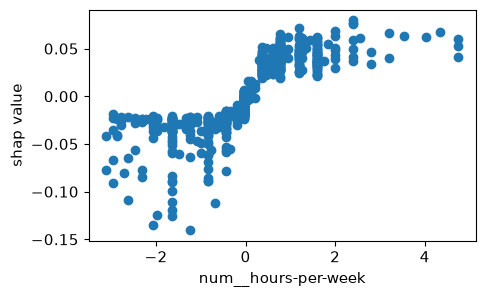

In [6]:
import matplotlib
matplotlib.rcParams.update({'font.size': 11})
ftr = 'num__hours-per-week'
indx = np.argwhere(feature_names==ftr)
plt.figure(figsize=(5,3))
plt.scatter(X_test_transformed[:1000,indx],shap_values[:,indx,1])
plt.ylabel('shap value')
plt.xlabel(ftr)
plt.show()


## Dependence plot

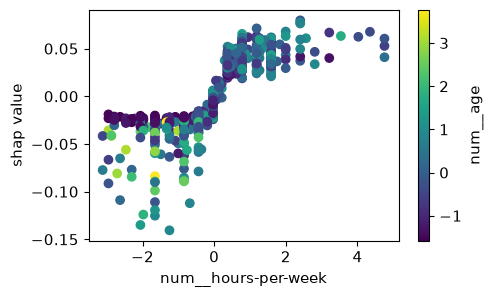

In [7]:
ftr1 = 'num__hours-per-week'
ftr2 = 'num__age'
indx1 = np.argwhere(feature_names==ftr1)
indx2 = np.argwhere(feature_names==ftr2)

plt.figure(figsize=(5,3))
plt.scatter(X_test_transformed[:1000,indx1],shap_values[:,indx1,1],c=X_test_transformed[:1000,indx2])
plt.ylabel('shap value')
plt.xlabel(ftr1)
plt.colorbar(label=ftr2)
plt.show()

## It can also be used for global feature importance

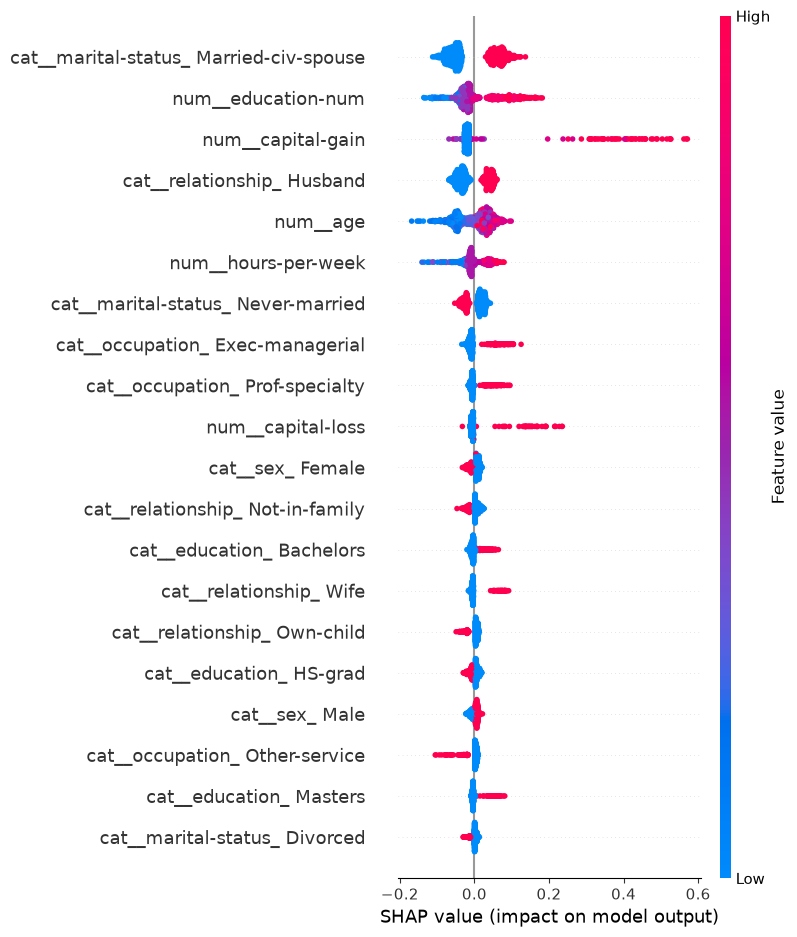

In [8]:
shap.summary_plot(shap_values[:,:,1], X_test_transformed[:1000],feature_names = feature_names)

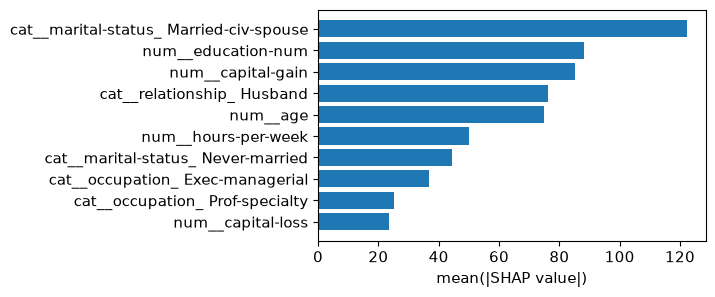

In [9]:
shap_summary = np.sum(np.abs(shap_values[:,:,1]),axis=0)+np.sum(np.abs(shap_values[:,:,0]),axis=0) # same shape as the number of features
indcs = np.argsort(shap_summary)
shap_summary[indcs]

plt.figure(figsize=(5,3))
plt.barh(feature_names[indcs[-10:]],shap_summary[indcs[-10:]])
plt.xlabel('mean(|SHAP value|)')
plt.show()

## SHAP cons
- it can be numerically expensive
   - an efficient shap method was developed for trees, see [here](https://arxiv.org/abs/1905.04610)
- how to estimate $f_x(S)$?
   - this is not trivial because models cannot change the number of features they use
   - usually the values of the dropped features are replaced with the mean or 0
   - this is approximate but no one came up with a better way 

## <font color='LIGHTGRAY'>Local feature importance metrics</font>
<font color='LIGHTGRAY'>By the end of this module, you will be able to</font>
- <font color='LIGHTGRAY'>Describe motivation behind local feature importance metrics</font>
- <font color='LIGHTGRAY'>Apply SHAP</font>
- **Describe LIME**

## Locally Interpretable Model-agnostic Explanations
- read about it [here](https://github.com/marcotcr/lime), [here](https://arxiv.org/abs/1602.04938), and [here](https://christophm.github.io/interpretable-ml-book/lime.html)
- classification and regression models can be complex and explaining the whole model is challenging
- let's focus on one point at a time
- generate an interpretable model (linear regression) in the local neighborhood of that one point 
- study the coefficients of that model

## LIME steps:
- select a data point you want to explain
- generate random samples
- weight the samples based on their distance from the data point of interest (exponential kernel)
- train a linear regression model (usually lasso) using the weighted samples
- study the local model around the point

<center><img src="../figures/LIME.jpg" width="600"></center>

## Cons, the devil is in the details
- the random samples are not taken around the data point of interest
- how to define the half width of the kernel?
   - the explanation can be very sensitive to the kernel width
   - there is no good way to define/measure what a good kernel width is
- the distance measure treats each feature equally which can be problematic

## Online book recommendation!
"Interpretable Machine Learning" by Christoph Molnar

https://christophm.github.io/interpretable-ml-book/

# Mudcard